In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from lprec import lpTransform

from utils import *

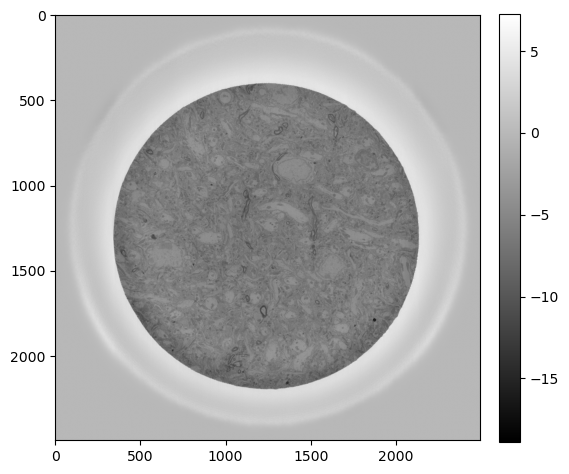

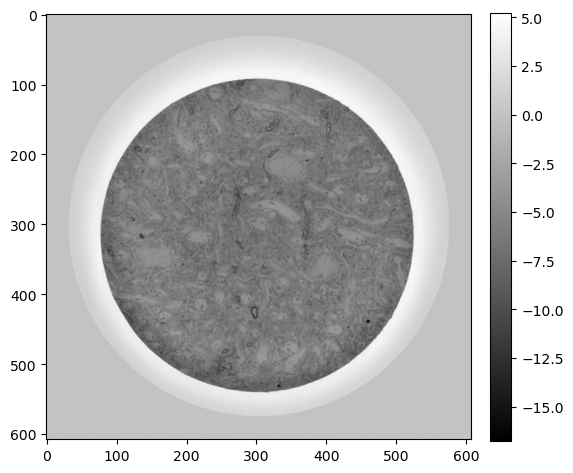

In [2]:
iter = 352
n=512+64+32
u = cp.array(read_tiff(f'/data2/vnikitin/brain_rec/20251115/Y350a4567_new/cascade_prb_init_10_0_45_4_4500_2048_0/rec_uz/{iter:04}.tiff'))
mshow(u,True)
from cupyx.scipy.ndimage import median_filter,zoom
u = median_filter(u, 5)
u = u[None]
u = zoom(u,[1,0.25,0.25],order=3)
u = u[:,u.shape[1]//2-n//2:u.shape[1]//2+n//2,u.shape[1]//2-n//2:u.shape[1]//2+n//2]

[x,y]=cp.meshgrid(cp.linspace(-1,1,n),cp.linspace(-1,1,n))
circ  =x**2+y**2<0.8
u*=circ
mshow(u[0],True)


In [3]:

N = n
Nproj = 2*N#int(3*N/2)
Nslices = 1
filter_type = 'none'
cor = N/2
interp_type = 'linear'
gpu = 0

# init random arrays
f = np.float32(np.random.random([Nslices, N, N]))
R = np.float32(np.random.random([Nslices, Nproj, N]))

# copy arrays to gpu
fg = cp.array(f)
Rg = cp.array(R)
# allocate gpu memory for results
Rfg = cp.zeros([Nslices, Nproj, N], dtype="float32")
fRg = cp.zeros([Nslices, N, N], dtype="float32")

# class lprec
lp = lpTransform.lpTransform(
    N, Nproj, Nslices, filter_type, cor, interp_type)
lp.precompute(1)
lp.initcmem(1, gpu)


def R(fg):
    Rfg = cp.zeros([Nslices, Nproj, N], dtype="float32")
    fg = cp.ascontiguousarray(fg)
    lp.fwdp(Rfg, fg, 0)
    return Rfg

def RT(Rfg):
    fg = cp.zeros([Nslices, N, N], dtype="float32")
    Rfg = cp.ascontiguousarray(Rfg)
    lp.adjp(fg, Rfg, 0)
    return fg

# compute with gpu pointers
Rfg = R(fg)
fRg = RT(Rg)

# self adjoint test
sum1 = sum(np.float64(np.ndarray.flatten(Rfg.get())*np.ndarray.flatten(Rg.get())))
sum2 = sum(np.float64(np.ndarray.flatten(fRg.get())*np.ndarray.flatten(fg.get())))
err0 = np.linalg.norm(sum1-sum2)/np.linalg.norm(sum2)
print(err0)


0.0015108052672246875


In [4]:
   def rec_tomo(d,u, niter=1):
    """Regular tomography reconstrution for initial guess"""

    def minf(Ru, d):
        return np.linalg.norm(Ru - d) ** 2
    
    Ru = R(u)
    tmp = np.empty_like(d)
    for k in range(niter):
        if k%32==0:
            print(f"{k} err={minf(Ru,d)}")
        tmp = 2 * (Ru - d)
        grad = RT(tmp)
        Rgrad = R(grad)
        if k == 0:
            eta = -grad
            Reta = -Rgrad
        else:
            beta = redot(Rgrad, Reta) / redot(Reta, Reta)
            eta = beta * eta - grad
            Reta = beta * Reta - Rgrad
        alpha = -redot(grad, eta) / (2 * redot(Reta, Reta))
        u += alpha * eta
        Ru += alpha * Reta        
    return u


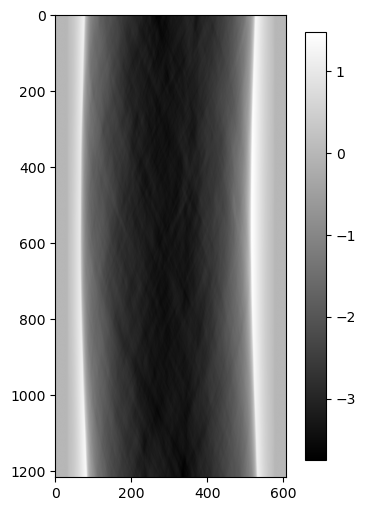

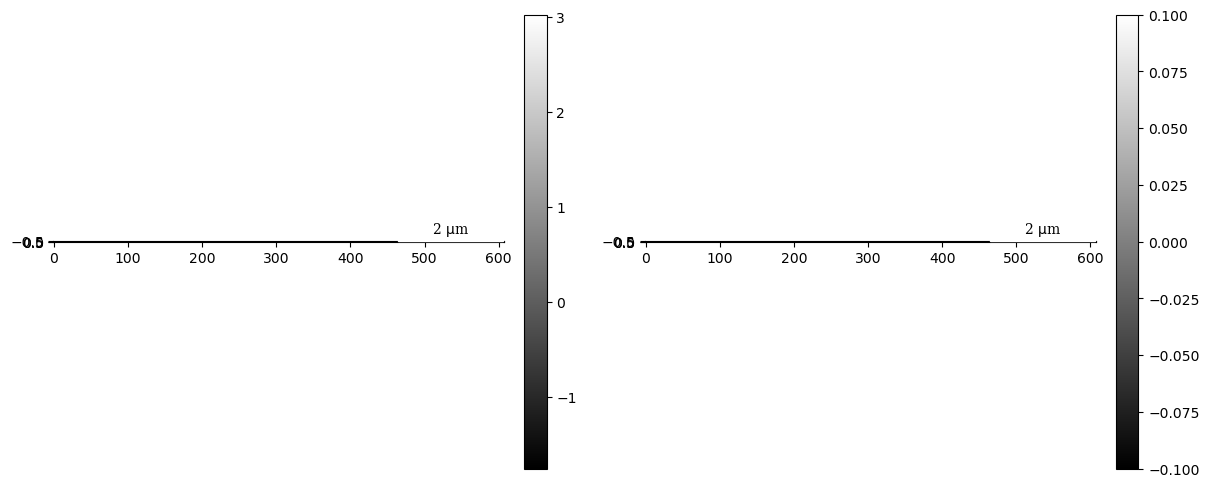

-634640.75
-635649.4
0 err=3834335.25
32 err=10.879287719726562
64 err=1.1318010091781616
96 err=0.3348994851112366
128 err=0.16540420055389404
160 err=0.10948963463306427
192 err=0.08612179011106491
224 err=0.07214178889989853
256 err=0.0626399889588356
288 err=0.056617315858602524
320 err=0.05496437847614288
352 err=0.059147290885448456
384 err=0.07626482099294662
416 err=0.1444983333349228
448 err=0.48431143164634705
480 err=4.19667387008667
512 err=313.82135009765625


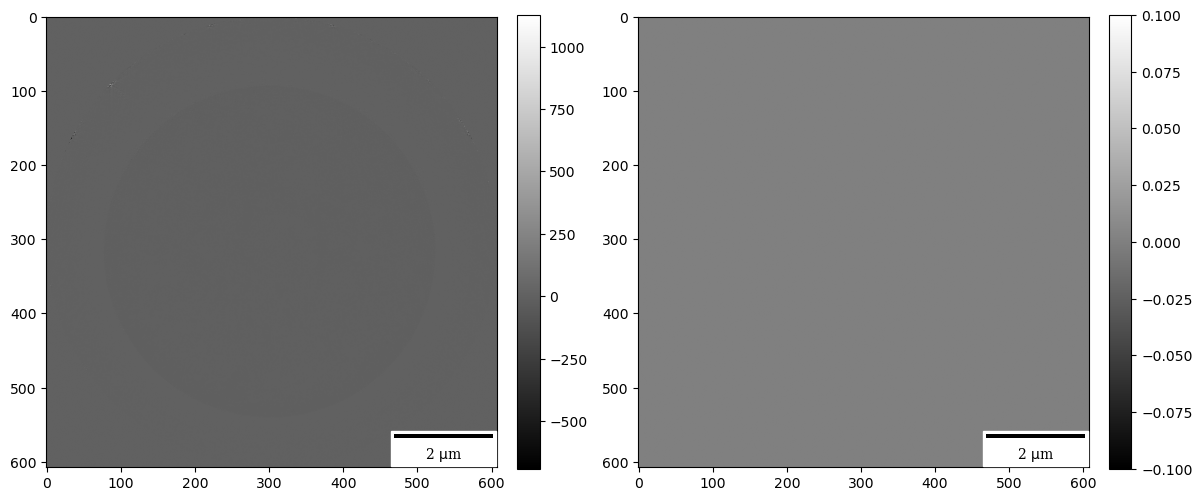

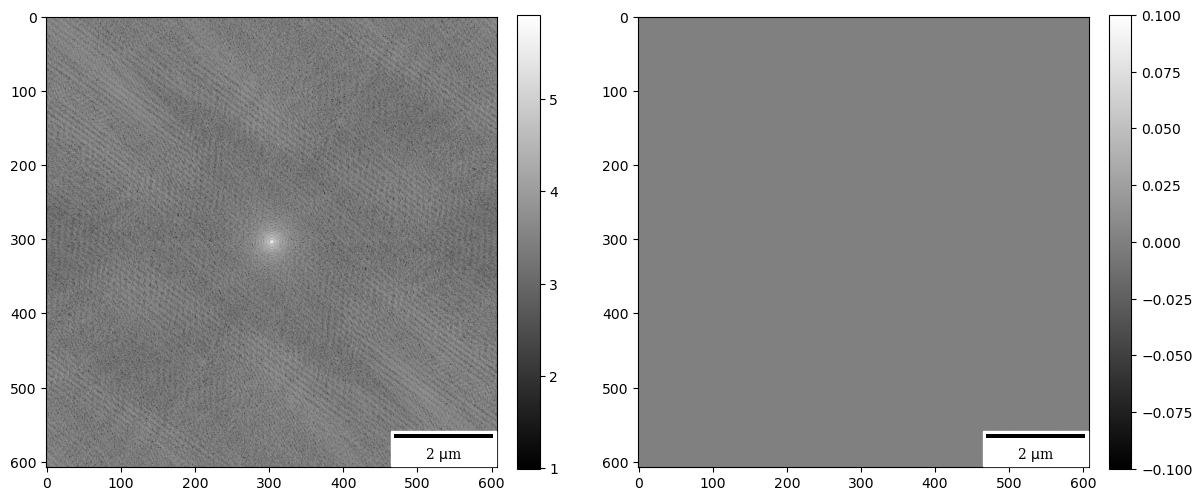

In [ ]:
cp.random.seed(0)
data = R(u)
mshow(data[0],True)
mshow_complex(cp.log10(cp.abs(cp.fft.fftshift(cp.fft.fft(cp.fft.fftshift(data)))))[:,0],True)
data1 = cp.random.random(data.shape).astype('float32')
u2 = RT(data1)
fu = cp.fft.fftshift(cp.fft.fft2(cp.fft.fftshift(u)))
# mshow_complex(u2[0],True)
print(cp.sum(data*cp.conj(data1)))
print(cp.sum(u*cp.conj(u2)))
# data+=(cp.random.random(data.shape)-0.5)*0.1

rec = rec_tomo(data,u*0,320)
frec = cp.fft.fftshift(cp.fft.fft2(cp.fft.fftshift(rec)))
mshow_complex(rec[0],True)
frec = cp.fft.fftshift(cp.fft.fft2(cp.fft.fftshift(rec)))
mshow_complex(cp.log10(cp.abs(frec[0])),True)

# mshow_complex(np.log10(np.abs(frec[0]-fu[0])),True)


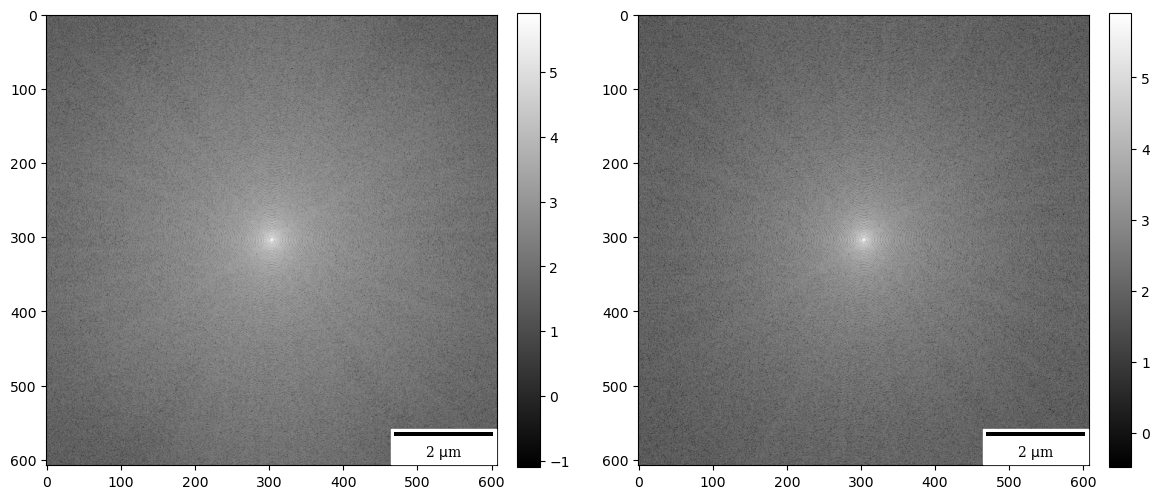

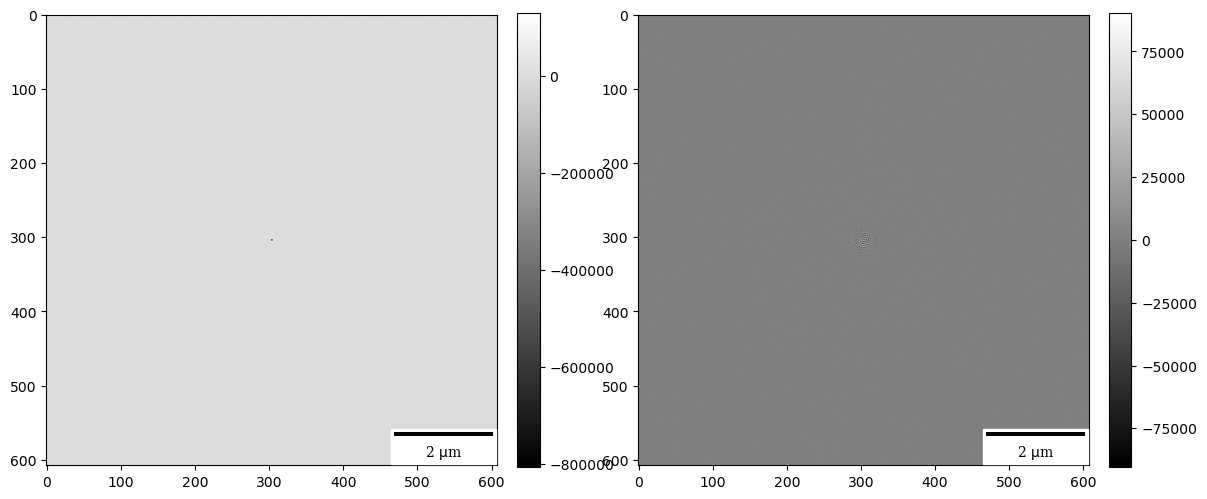

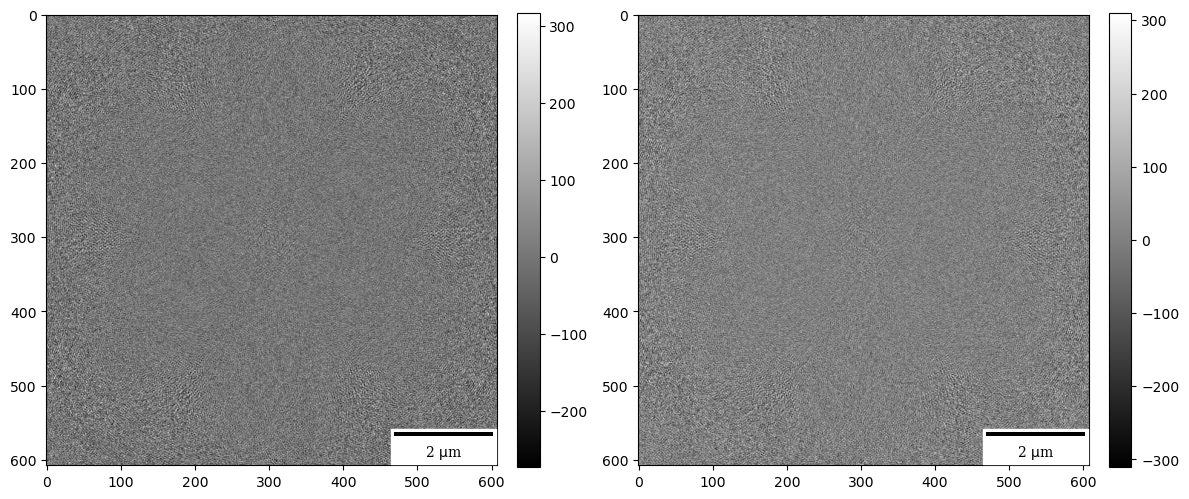

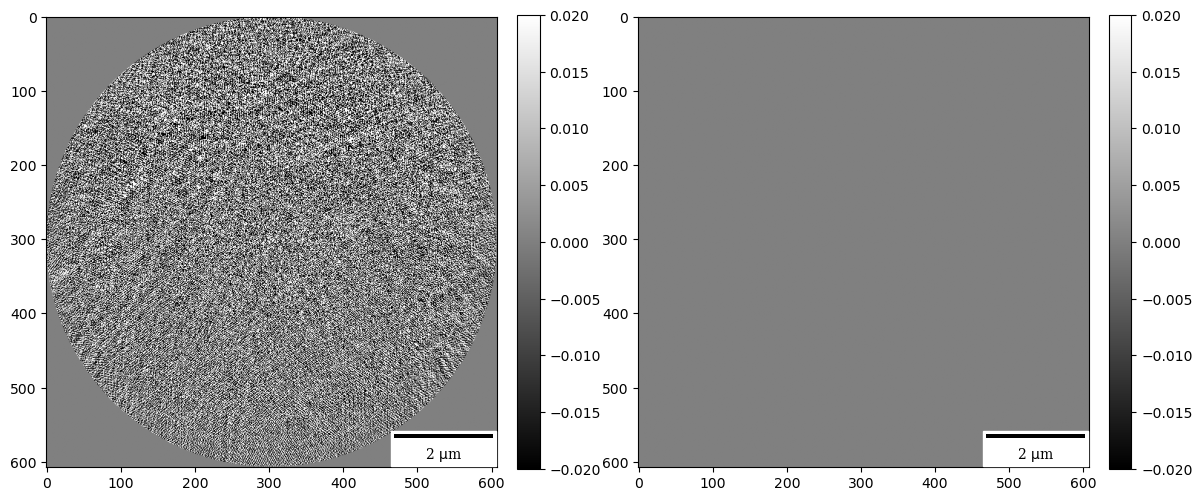

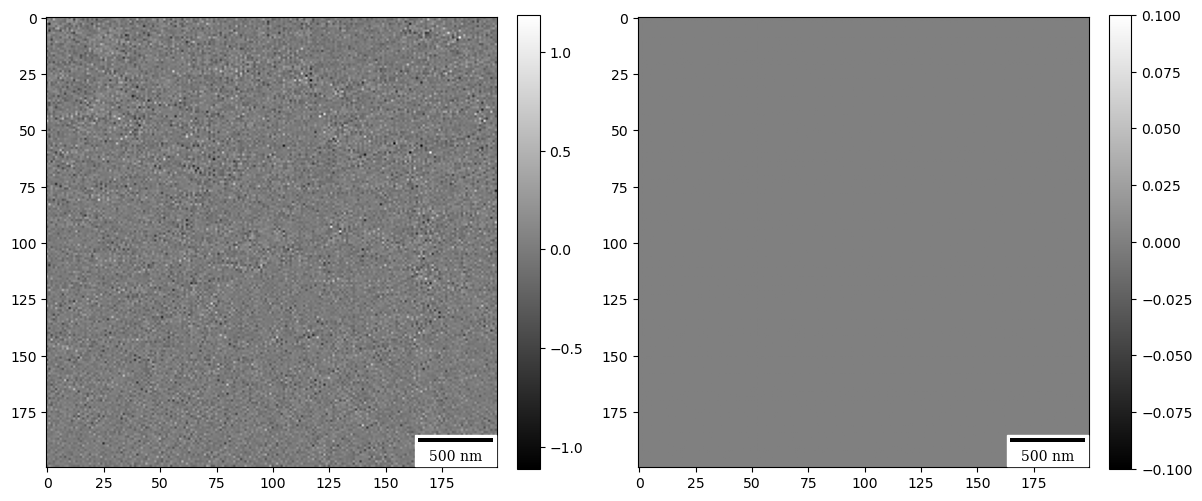

In [6]:
mshow_complex(np.log10(np.abs(frec[0]))+1j*np.log10(np.abs(fu[0])),True)
mshow_complex(frec[0],True)
mshow_complex(frec[0]-fu[0],True)

mshow_complex(rec[0]-u[0],True,vmax=0.02,vmin=-0.02)

mshow_complex(rec[0,n//2-100:n//2+100,n//2-100:n//2+100]-u[0,n//2-100:n//2+100,n//2-100:n//2+100],True)